# SlideMix demo

This notebook runs the SlideMix augmentation on two CAMELYON16 lymph node sections, one normal and one with breast cancer metastasis, and visualizes each step. It does not train a model.

1. Tile the two slides
2. Embed the tiles with GigaPath and CONCH
3. Select ROI tiles (VARS) and compute VLM class scores
4. Align the two slides
5. Mix tiles with In-place Tile Shuffling (ITS) at block sizes N = 8, 4, 2
6. Compute the soft label of the mixed slide

Requirements:

- a GPU runtime (in Colab: Runtime > Change runtime type > GPU)
- a Hugging Face account with access to [prov-gigapath/prov-gigapath](https://huggingface.co/prov-gigapath/prov-gigapath) and [MahmoodLab/conch](https://huggingface.co/MahmoodLab/conch)
- the demo set of slides
- optional: a [Gemini API key](https://aistudio.google.com/apikey) to run the full VARS with Gemini and PubMed retrieval

## Setup

In [1]:
import os
import subprocess
import sys

if not os.path.exists("utils/slidemix.py"):
    if not os.path.exists("SlideMix"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Xia-Research-Lab/SlideMix.git"], check=True)
    os.chdir("SlideMix")
sys.path.insert(0, os.getcwd())

try:
    import openslide
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openslide-bin", "openslide-python"], check=True)
    import openslide

In [2]:
import numpy as np
import pandas as pd
import torch
import timm
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from pathlib import Path
from PIL import Image
from scipy import ndimage
from skimage.filters import threshold_otsu
from huggingface_hub import get_token, login
from safetensors.torch import load_file, save_file

from utils.slidemix import (
    align_moving_to_reference,
    coords_to_grid,
    fit_pca_stats,
    its_mix,
    soft_cls_target,
    vlm_evidence_weights,
)
from utils.slidemix_vlm import ConchTextEncoder
from tools.slidemix_var_selector import (
    DEFAULT_REGION_PROMPT,
    GeminiRegionDescriber,
    _conch_description,
    ground_description,
    select_roi_for_slide,
    task_context,
    threshold_mask,
)
from tools.slidemix_rag import BiomedCLIPEncoder, Retriever, build_index, dataset_query_info, default_queries, fetch_pubmed
from tools.slidemix_vlm_scores import build_task_class_embeddings, score_slide

assert torch.cuda.is_available(), "No GPU found. In Colab, switch to a GPU runtime (Runtime > Change runtime type > GPU)."
device = "cuda"
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(torch.cuda.get_device_name(0), dtype)

if get_token() is None:
    login()

NVIDIA H200 NVL torch.bfloat16


### Gemini API key (optional)

With a Gemini API key, VARS describes each slide thumbnail with Gemini and grounds the description and the VLM class prompts in retrieved PubMed abstracts, as in the paper. Without a key, the notebook runs the CONCH-only variant without retrieval. Paste the key below, set the `GEMINI_API_KEY` environment variable, or add it to Colab Secrets under the name `GEMINI_API_KEY`.

In [3]:
GEMINI_API_KEY = ""
GEMINI_MODEL = "gemini-3.1-pro-preview"

if not GEMINI_API_KEY:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY", "")
if not GEMINI_API_KEY:
    try:
        from google.colab import userdata

        GEMINI_API_KEY = userdata.get("GEMINI_API_KEY") or ""
    except Exception:
        pass

USE_GEMINI = bool(GEMINI_API_KEY)
if USE_GEMINI:
    os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
    try:
        import google.genai
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-genai"], check=True)
    print(f"Gemini key found: VARS uses {GEMINI_MODEL} and PubMed retrieval")
else:
    print("No Gemini key: VARS uses CONCH only and the VLM scores use no retrieval (VLM/u)")

No Gemini key: VARS uses CONCH only and the VLM scores use no retrieval (VLM/u)


## Demo set

The demo set contains two CAMELYON16 slides and their labels:

```
demo_set/
  slides/<image_id>.tif
  labels.csv                # image_id, label
```

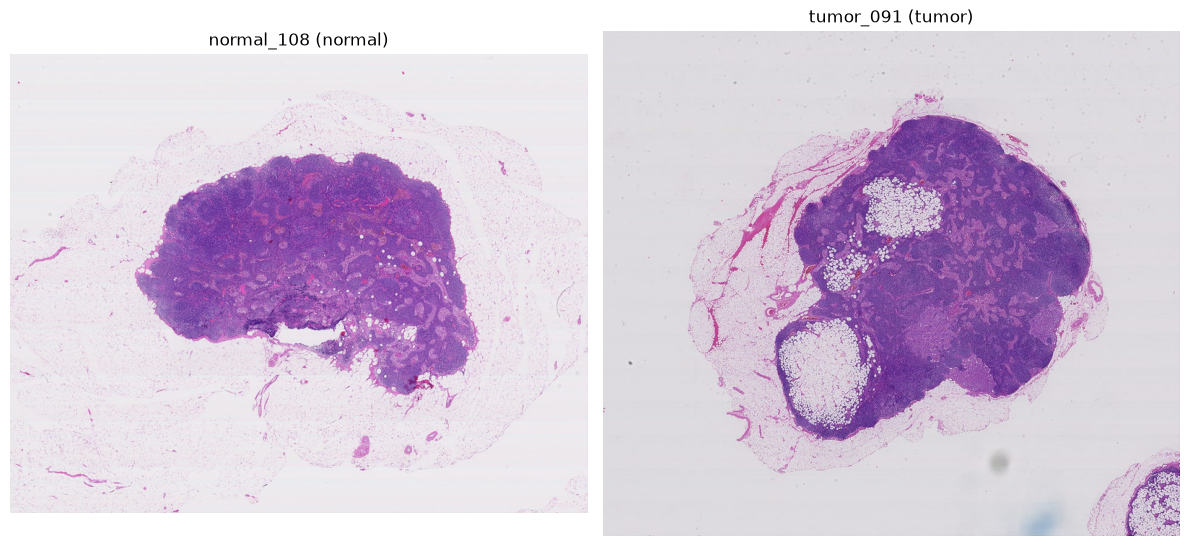

In [4]:
DEMO_URL = "https://github.com/Xia-Research-Lab/SlideMix/releases/download/demo-data/demo_set.zip"
DEMO_DIR = Path("demo_set")

if not DEMO_DIR.exists() and DEMO_URL:
    import urllib.request
    import zipfile

    urllib.request.urlretrieve(DEMO_URL, "demo_set.zip")
    with zipfile.ZipFile("demo_set.zip") as z:
        z.extractall(".")

slide_paths = sorted((DEMO_DIR / "slides").glob("*.tif"))
labels = pd.read_csv(DEMO_DIR / "labels.csv").set_index("image_id")

DATASET = "CAMELYON16"
TASK = "BREAST_METASTASIS"
CLASSES = ["normal", "tumor"]
REF_ID, MOV_ID = [p.stem for p in slide_paths[:2]]
y_ref, y_mov = (CLASSES.index(labels.loc[sid, "label"]) for sid in (REF_ID, MOV_ID))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, sid, y in zip(axes, (REF_ID, MOV_ID), (y_ref, y_mov)):
    s = openslide.OpenSlide(str(DEMO_DIR / "slides" / f"{sid}.tif"))
    ax.imshow(s.get_thumbnail((800, 800)))
    ax.set_title(f"{sid} ({CLASSES[y]})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 1. Tiling

Each slide is cut into 224 x 224 tiles at 0.5 µm/px. Tissue is found with an Otsu threshold on a low-resolution level, and tiles with less than 10% tissue are dropped. Tiling takes a few minutes per slide.

In [5]:
TILE_SIZE, TARGET_MPP, MIN_TISSUE = 224, 0.5, 0.1


def luminance(rgb):
    return rgb[..., :3] @ np.array([0.2126, 0.7152, 0.0722])


def tile_slide(path):
    slide = openslide.OpenSlide(str(path))
    mpp = float(slide.properties.get(openslide.PROPERTY_NAME_MPP_X, TARGET_MPP))
    step = int(round(TILE_SIZE * TARGET_MPP / mpp))
    read_level = max(l for l in range(slide.level_count) if slide.level_downsamples[l] * mpp <= TARGET_MPP * 1.01)
    read_ds = slide.level_downsamples[read_level]
    read_size = int(round(step / read_ds))

    mask_level = min((l for l in range(slide.level_count) if max(slide.level_dimensions[l]) <= 4000), default=slide.level_count - 1)
    ds = slide.level_downsamples[mask_level]
    thumb = np.asarray(slide.read_region((0, 0), mask_level, slide.level_dimensions[mask_level]).convert("RGB"), dtype=np.float32)
    lum = luminance(thumb)
    thr = threshold_otsu(lum)
    mask = ndimage.binary_closing(lum < thr)

    W, H = slide.dimensions
    tiles, coords = [], []
    for y in range(0, H - step + 1, step):
        for x in range(0, W - step + 1, step):
            m = mask[int(y / ds) : int((y + step) / ds) + 1, int(x / ds) : int((x + step) / ds) + 1]
            if m.size == 0 or m.mean() < MIN_TISSUE:
                continue
            tile = slide.read_region((x, y), read_level, (read_size, read_size)).convert("RGB")
            if read_size != TILE_SIZE:
                tile = tile.resize((TILE_SIZE, TILE_SIZE), Image.Resampling.LANCZOS)
            arr = np.asarray(tile)
            if (luminance(arr.astype(np.float32)) < thr).mean() < MIN_TISSUE or arr.reshape(-1, 3).std(0).mean() < 5:
                continue
            tiles.append(arr)
            coords.append((y, x))
    return np.stack(tiles), torch.tensor(coords, dtype=torch.int64)


slides = {}
for sid in (REF_ID, MOV_ID):
    tiles, coords = tile_slide(DEMO_DIR / "slides" / f"{sid}.tif")
    slides[sid] = {"tiles": tiles, "coords_yx": coords}
    print(f"{sid}: {len(tiles)} tiles")

normal_108: 1554 tiles


tumor_091: 3871 tiles


## 2. Tile embeddings

GigaPath embeddings (1536-d) are the features that SlideMix mixes and the MIL model is trained on. CONCH embeddings (512-d) share a space with CONCH text embeddings and are used for VARS and the VLM soft labels. The embeddings are saved in the same layout as the training data.

In [6]:
from models.CONCH.open_clip_custom import create_model_from_pretrained, get_tokenizer, tokenize


@torch.inference_mode()
def embed(tiles, fn, batch_size=128):
    out = []
    for i in range(0, len(tiles), batch_size):
        out.append(fn(tiles[i : i + batch_size]).float().cpu())
    return torch.cat(out)


gigapath = timm.create_model("hf_hub:prov-gigapath/prov-gigapath", pretrained=True, num_classes=0).eval().to(device, dtype)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def gigapath_fn(batch):
    x = torch.from_numpy(batch).to(device).permute(0, 3, 1, 2).float() / 255.0
    return gigapath(((x - mean) / std).to(dtype))


conch, conch_preprocess = create_model_from_pretrained("conch_ViT-B-16", "hf_hub:MahmoodLab/conch", device=device)
conch.eval()


def conch_fn(batch):
    x = torch.stack([conch_preprocess(Image.fromarray(t)) for t in batch]).to(device)
    with torch.autocast("cuda", dtype=dtype):
        return conch.encode_image(x, proj_contrast=True, normalize=False)


for sid, s in slides.items():
    for folder, fn, key in (("tiles-embeddings", gigapath_fn, "features"), ("tiles-embeddings_conch", conch_fn, "conch_features")):
        path = DEMO_DIR / folder / f"{sid}.safetensors"
        if path.exists():
            s[key] = load_file(path)["features"]
        else:
            s[key] = embed(s["tiles"], fn)
            path.parent.mkdir(parents=True, exist_ok=True)
            save_file({"features": s[key], "coords_yx": s["coords_yx"]}, path)
    print(f"{sid}: GigaPath {tuple(s['features'].shape)}, CONCH {tuple(s['conch_features'].shape)}")

del gigapath
torch.cuda.empty_cache()

normal_108: GigaPath (1554, 1536), CONCH (1554, 512)
tumor_091: GigaPath (3871, 1536), CONCH (3871, 512)


## 3. VARS and VLM class scores

VARS selects the ROI tiles of each slide. A region description is grounded in the CONCH tile embeddings and the top 25% of tiles are kept. An `N x N` block of tiles can only be swapped if at least 25% of its `N x N` positions hold an ROI tile of either slide. The fraction is taken over the full block, so blocks at the tissue edge are not favored. The VLM scores are per-tile CONCH probabilities for each class and weight the soft label.

With a Gemini key, the notebook builds a small PubMed corpus for the task, Gemini describes the diagnostically relevant regions of each slide thumbnail using the retrieved abstracts, and the VLM class prompts include the retrieved literature, as in the paper. Without a key, the region description is a fixed prompt and the VLM scores use no retrieved literature, which corresponds to the VLM/u setting of the paper.

In the heatmaps, the evidence is rescaled to the minimum and maximum of each slide, so colors are relative within a slide.

In [7]:
text_encoder = ConchTextEncoder(device=device, loader=lambda *args: (conch, get_tokenizer(), tokenize))
label_dict = {c: i for i, c in enumerate(CLASSES)}
task_ctx = task_context(DATASET)
retriever = None

if USE_GEMINI:
    rag_dir = DEMO_DIR / "rag"
    docs_path = rag_dir / "docs.jsonl"
    if not docs_path.exists():
        organ, tasks, task_labels = dataset_query_info(DATASET)
        fetch_pubmed(default_queries(organ, tasks, task_labels), 50, docs_path)
    rag_encoder = BiomedCLIPEncoder(device=device)
    if not (rag_dir / "index" / "meta.json").exists():
        build_index(docs_path, rag_dir / "index", rag_encoder)
    retriever = Retriever(rag_dir / "index", rag_encoder)
    print(f"PubMed corpus: {len(retriever.docs)} abstracts")

    describer = GeminiRegionDescriber(model=GEMINI_MODEL, cache_path=DEMO_DIR / "roi" / "gemini_cache.json")
    for sid, s in slides.items():
        r = select_roi_for_slide(
            sid, "gemini", DEMO_DIR / "tiles-embeddings" / f"{sid}.safetensors", DEMO_DIR / "roi",
            conch_path=DEMO_DIR / "tiles-embeddings_conch" / f"{sid}.safetensors",
            text_encoder=text_encoder, describer=describer, retriever=retriever,
            wsi_dir=DEMO_DIR / "slides", task_ctx=task_ctx, overwrite=True,
        )
        if r["fallback"]:
            print(f"WARNING {sid}: {r['fallback']}")
        print(f"{sid} ({r['effective_mode']}): {r['description']}")
        print(f"  PubMed: {', '.join(r['pmids'])}")
        s["roi_mask"] = load_file(DEMO_DIR / "roi" / f"{sid}.safetensors")["roi_mask"].bool()
else:
    description = _conch_description(task_ctx, DEFAULT_REGION_PROMPT, [])
    print("VARS description:", description)
    for sid, s in slides.items():
        sims = ground_description(text_encoder, description, s["conch_features"], s["coords_yx"], s["coords_yx"])
        s["roi_mask"] = torch.from_numpy(threshold_mask(sims))

class_embs = build_task_class_embeddings(text_encoder, DATASET, {TASK: label_dict}, retriever=retriever)
if retriever is not None:
    print("VLM class prompt context:", class_embs[TASK][1])
for sid, s in slides.items():
    s["scores"] = score_slide(s["conch_features"], s["coords_yx"], s["coords_yx"], class_embs, text_encoder.logit_scale)[TASK]

VARS description: Lymph Node, H&E staining, tasks: BREAST_METASTASIS (normal, tumor). Identify key pathological regions in this WSI.


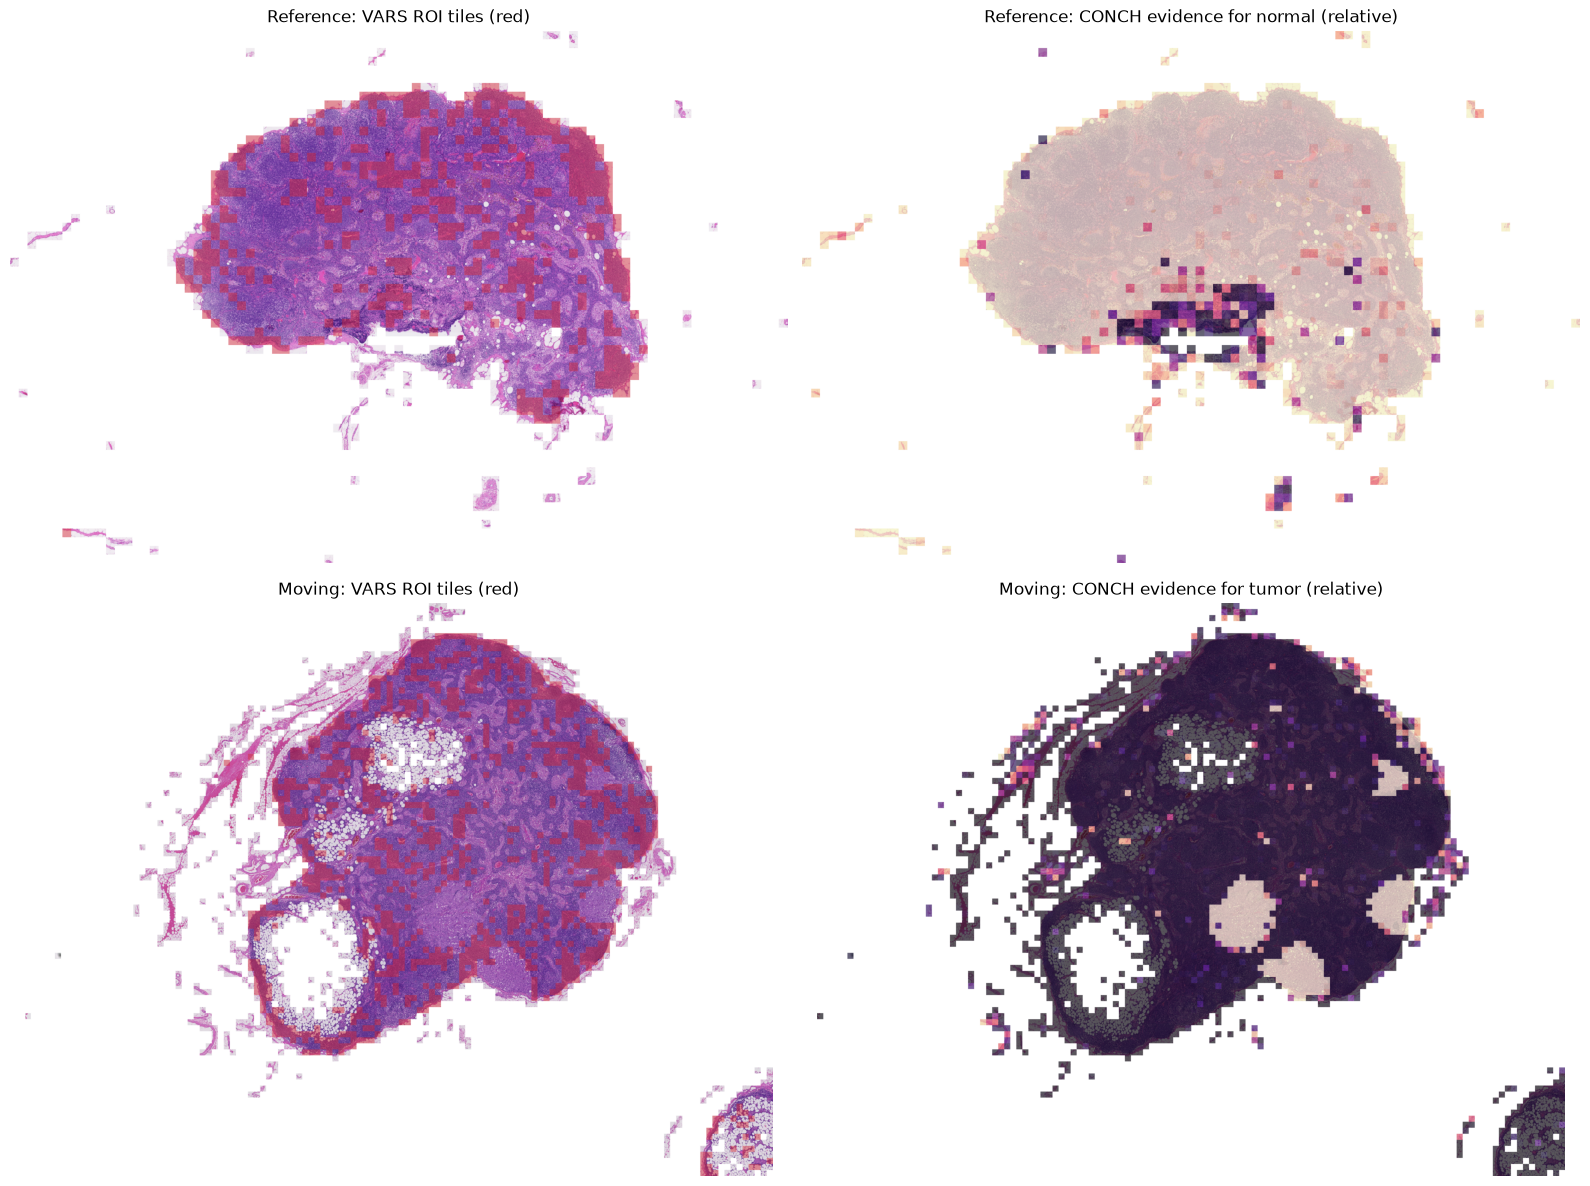

In [8]:
REF_COLOR = np.array([0.29, 0.48, 0.82])
MOV_COLOR = np.array([0.91, 0.64, 0.24])
ref, mov = slides[REF_ID], slides[MOV_ID]
grid_r, _ = coords_to_grid(ref["coords_yx"])
grid_m, _ = coords_to_grid(mov["coords_yx"])


def canvas(grids):
    allg = np.concatenate(grids)
    origin = allg.min(0)
    return origin, tuple((allg.max(0) - origin + 1).tolist())


def cell_size(shape):
    return int(np.clip(2400 // max(shape), 6, 32))


def small(tiles, cell):
    return np.stack([np.asarray(Image.fromarray(t).resize((cell, cell), Image.Resampling.BILINEAR)) for t in tiles])


def mosaic(grid, thumbs, origin, shape, cell, overlay=None, alpha=0.45, outline=None):
    img = np.full((shape[0] * cell, shape[1] * cell, 3), 255, dtype=np.float32)
    for k, (r, c) in enumerate((grid - origin).tolist()):
        block = thumbs[k].astype(np.float32)
        if overlay is not None and overlay[k] is not None:
            block = (1 - alpha) * block + alpha * 255 * np.asarray(overlay[k])
        if outline is not None and outline[k] is not None:
            block[:2], block[-2:], block[:, :2], block[:, -2:] = [255 * np.asarray(outline[k])] * 4
        img[r * cell : (r + 1) * cell, c * cell : (c + 1) * cell] = block
    return img.astype(np.uint8)


def show(ax, img, title):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")


o_r, sh_r = canvas([grid_r])
o_m, sh_m = canvas([grid_m])
cell = cell_size(max(sh_r, sh_m))
thumbs_r, thumbs_m = small(ref["tiles"], cell), small(mov["tiles"], cell)

RED = np.array([0.85, 0.15, 0.2])
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for row, (name, s, g, th, o, sh, y) in enumerate(
    (("Reference", ref, grid_r, thumbs_r, o_r, sh_r, y_ref), ("Moving", mov, grid_m, thumbs_m, o_m, sh_m, y_mov))
):
    roi = s["roi_mask"].numpy()
    show(axes[row, 0], mosaic(g, th, o, sh, cell, overlay=[RED if r else None for r in roi]), f"{name}: VARS ROI tiles (red)")
    p = s["scores"][:, y].numpy()
    heat = plt.cm.magma((p - p.min()) / (p.max() - p.min() + 1e-8))[:, :3]
    show(axes[row, 1], mosaic(g, th, o, sh, cell, overlay=list(heat), alpha=0.6), f"{name}: CONCH evidence for {CLASSES[y]} (relative)")
plt.tight_layout()
plt.show()

## 4. Alignment

The moving tissue is placed onto the convex hull of the reference tissue so that swapped tiles land on tissue rather than background.

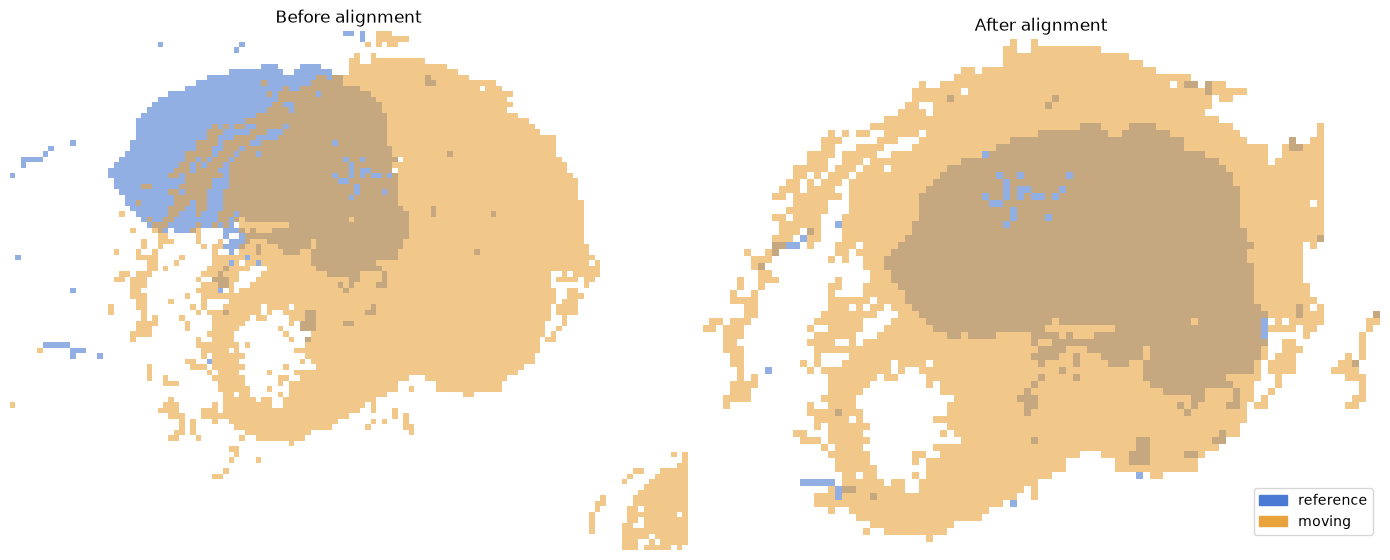

reference tiles covered by the moving slide: 1516/1554


In [9]:
aligned_m = align_moving_to_reference(grid_r, grid_m)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, g_m, title in ((axes[0], grid_m, "Before alignment"), (axes[1], aligned_m, "After alignment")):
    o, sh = canvas([grid_r, g_m])
    img = np.ones(sh + (3,))
    img[tuple((grid_r - o).T)] = 0.4 * img[tuple((grid_r - o).T)] + 0.6 * REF_COLOR
    img[tuple((g_m - o).T)] = 0.4 * img[tuple((g_m - o).T)] + 0.6 * MOV_COLOR
    ax.imshow(img, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
axes[1].legend(handles=[Patch(color=REF_COLOR, label="reference"), Patch(color=MOV_COLOR, label="moving")], loc="lower right")
plt.tight_layout()
plt.show()

covered = {tuple(c) for c in grid_r.tolist()} & {tuple(c) for c in aligned_m.tolist()}
print(f"reference tiles covered by the moving slide: {len(covered)}/{len(grid_r)}")

## 5. In-place Tile Shuffling (ITS)

ITS splits the reference slide into `N x N` blocks of tiles. A block is eligible if at least 25% of its `N x N` positions hold an ROI tile of either slide and, when `T_PCA` < 1, if the average PCA distance between its reference and moving tiles is below `T_PCA`. A fraction `P` of the eligible blocks is chosen at random, and every tile in a chosen block is replaced by the moving tile aligned onto it; positions without moving tissue keep the reference tile. The mixed slide keeps the coordinates of the reference slide.

During training, the curriculum shrinks `N` from 16 to 1 while it tightens `T_PCA` and raises `P`. The figures below fix an easy `T_PCA` of 0.8 and `P` = 0.4 and show `N` = 8, 4 and 2. The PCA statistics for the `T_PCA` filter are fitted on the training split during training; here they are fitted on the two demo slides.

Each tile shows the tissue whose embedding it now carries. Tiles taken from the moving slide are tinted orange, and each `N x N` block that received tiles is outlined.

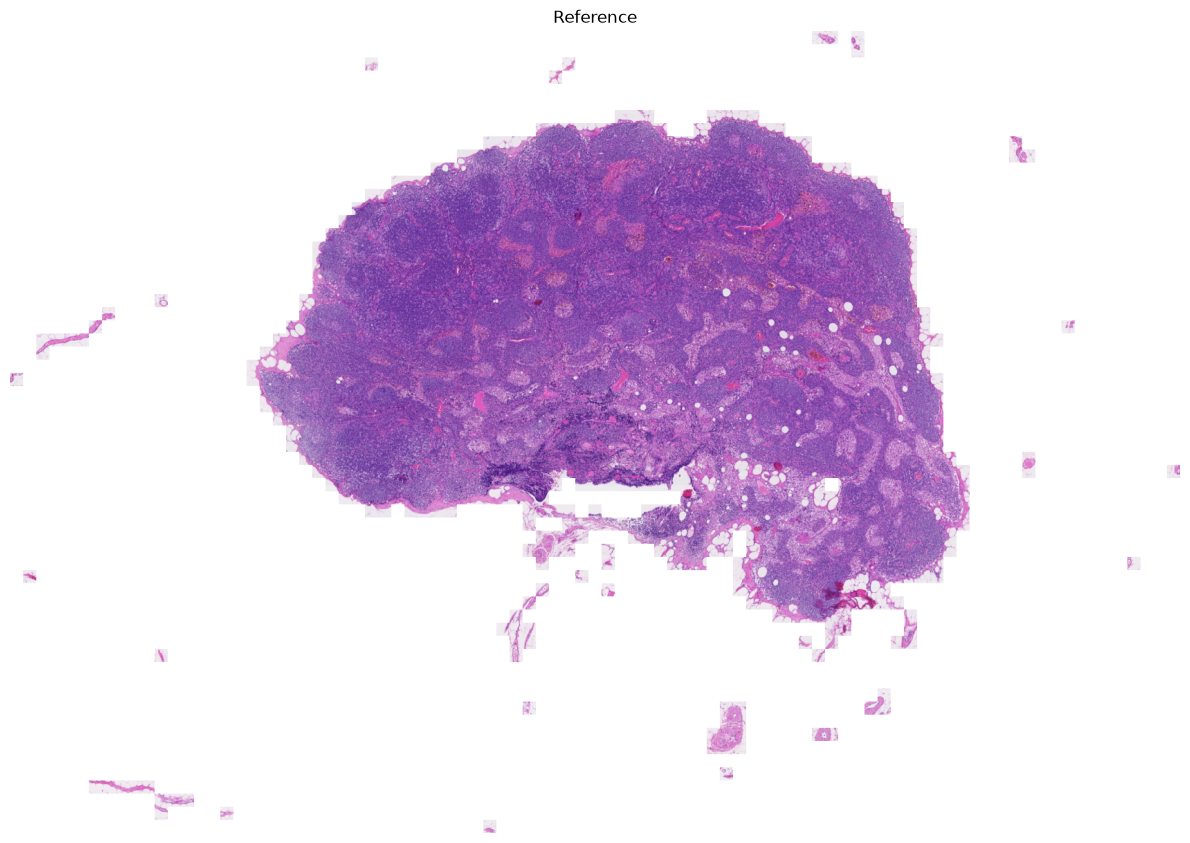

N=8: 524/1109 tiles swapped


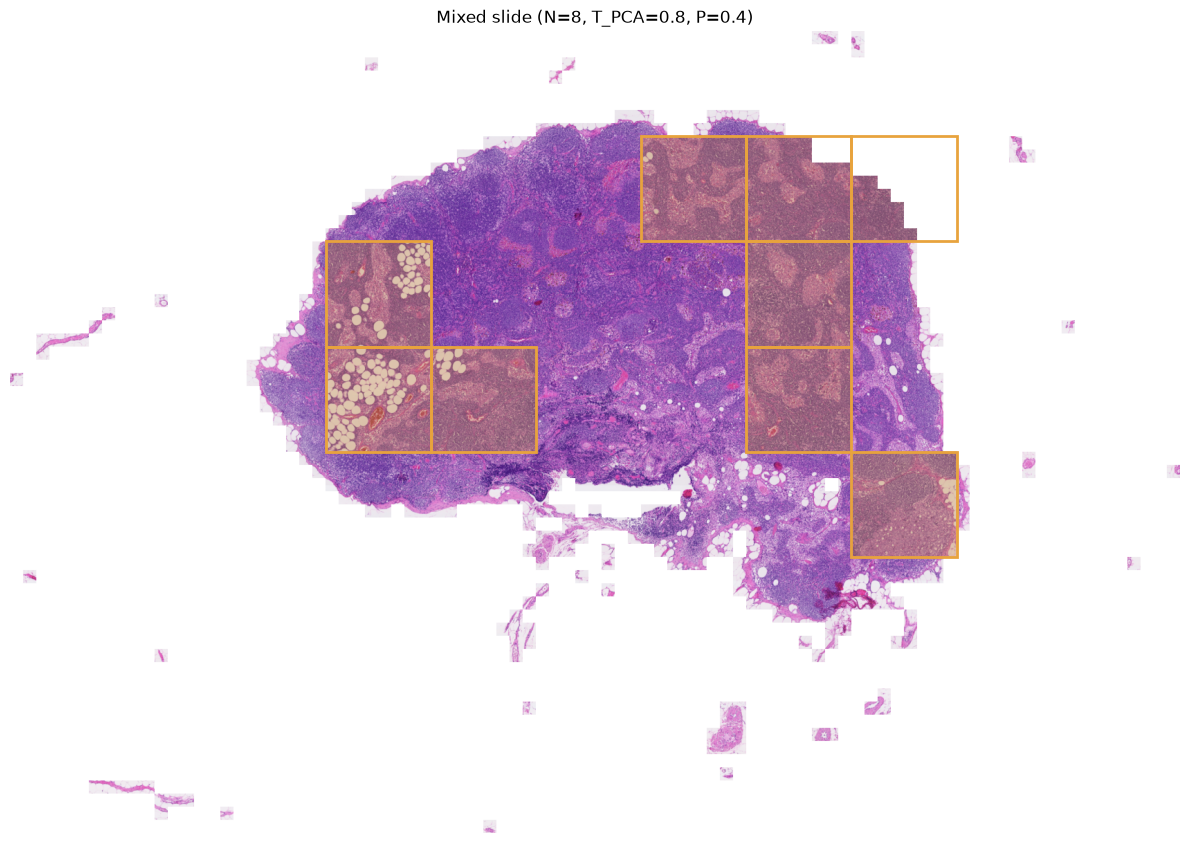

N=4: 442/1080 tiles swapped


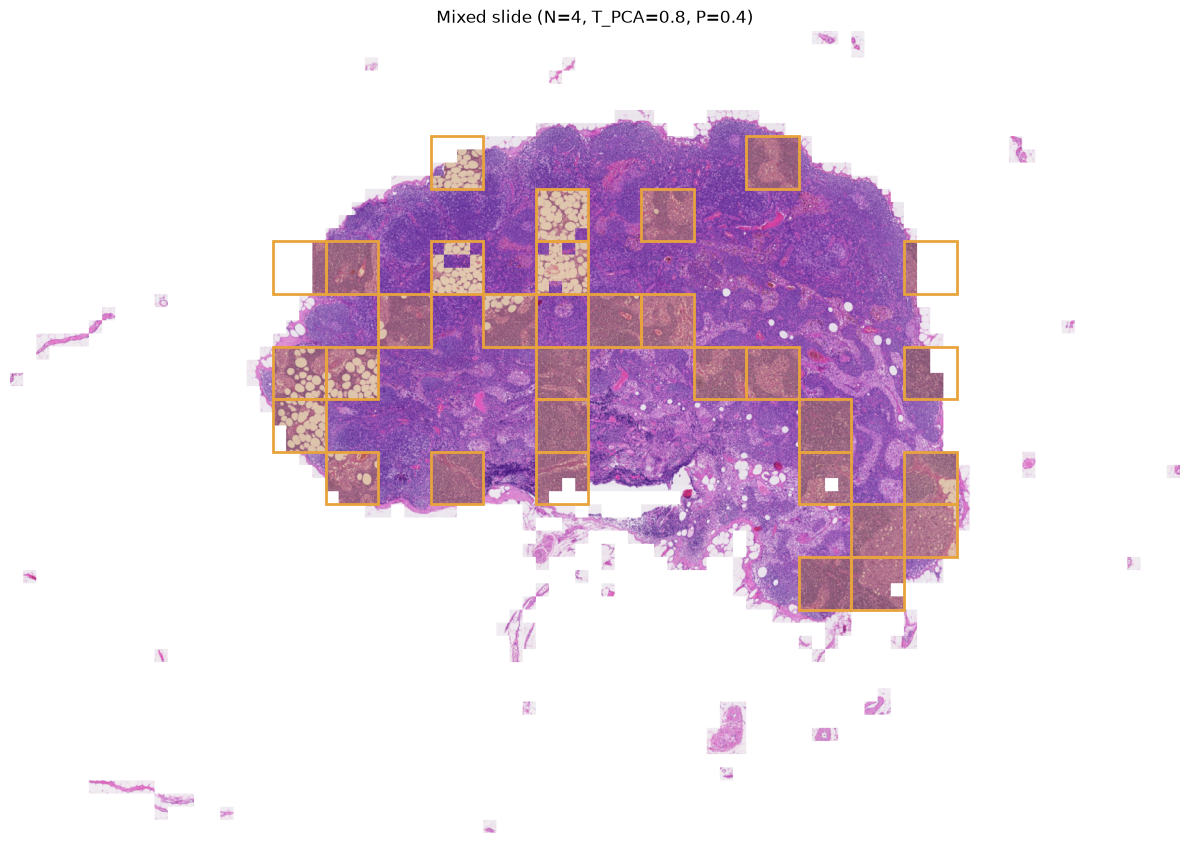

N=2: 451/1122 tiles swapped


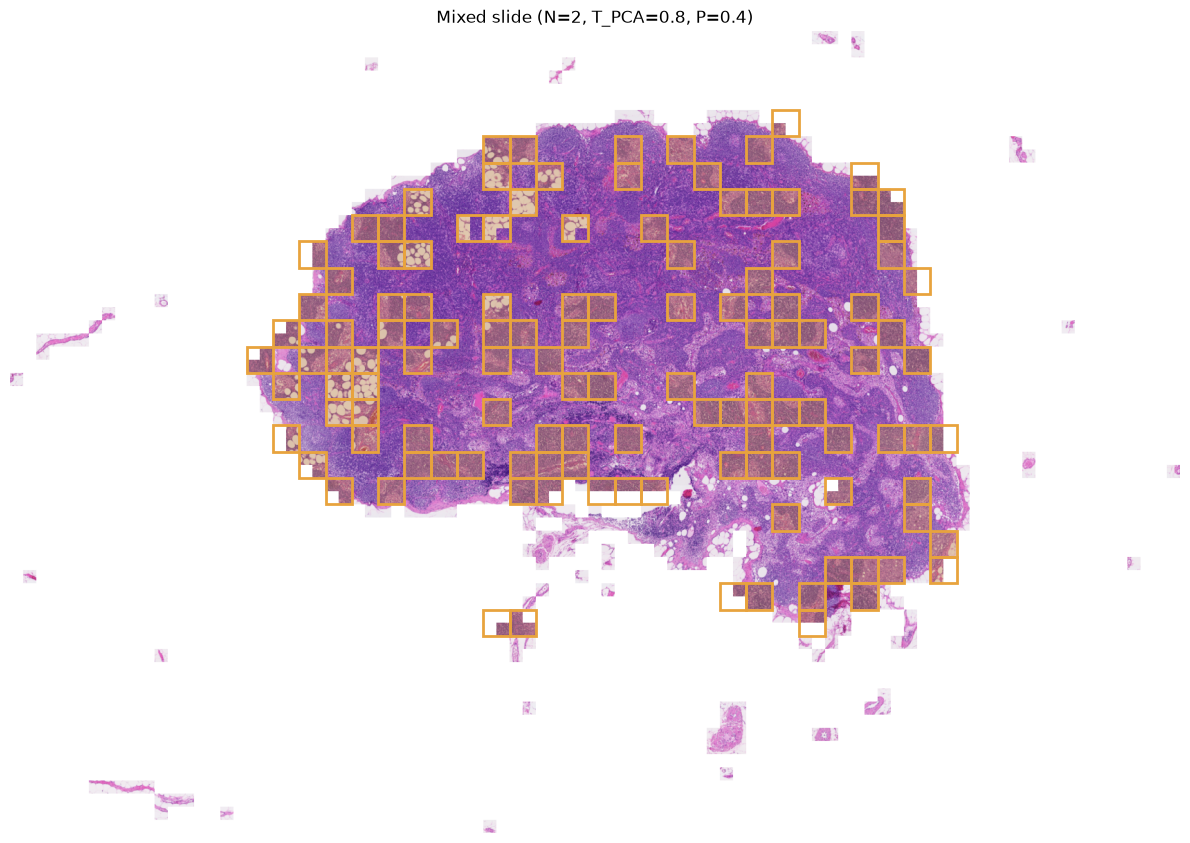

In [10]:
def show_mix(ax, m, N, title):
    src = m.source.numpy().astype(bool)
    mi = m.moving_index.numpy()
    th = np.where(src[:, None, None, None], thumbs_m[np.maximum(mi, 0)], thumbs_r)
    show(ax, mosaic(grid_r, th, o_r, sh_r, cell, overlay=[MOV_COLOR if x else None for x in src], alpha=0.3), title)
    for by, bx in np.unique(grid_r[src] // N, axis=0):
        y0, x0 = by * N - o_r[0], bx * N - o_r[1]
        ax.add_patch(Rectangle((x0 * cell - 0.5, y0 * cell - 0.5), N * cell, N * cell, fill=False, edgecolor=MOV_COLOR, linewidth=2))


P, T_PCA = 0.4, 0.8
pca_stats = fit_pca_stats([ref["features"], mov["features"]], k=16, seed=0)

fig, ax = plt.subplots(figsize=(12, 9))
show(ax, mosaic(grid_r, thumbs_r, o_r, sh_r, cell), "Reference")
plt.tight_layout()
plt.show()

mixes = {}
for N in (8, 4, 2):
    m = its_mix(
        ref["features"], ref["coords_yx"], mov["features"], mov["coords_yx"],
        N=N, P=P, T_PCA=T_PCA, roi_r=ref["roi_mask"], roi_m=mov["roi_mask"], pca_stats=pca_stats, rng=N,
    )
    mixes[N] = m
    print(f"N={N}: {m.n_swapped}/{m.n_eligible} tiles swapped")
    fig, ax = plt.subplots(figsize=(12, 9))
    show_mix(ax, m, N, f"Mixed slide (N={N}, T_PCA={T_PCA}, P={P})")
    plt.tight_layout()
    plt.show()

## 6. Soft labels

The label of the mixed slide combines the labels of both slides. `linear` weights them by the share of tiles from each slide, `random` picks one slide, and `vlm` weights them by the CONCH evidence for each slide's label in the tiles that slide contributed.

reference: normal, moving: tumor, share of reference tiles: 0.72
VLM evidence: reference 1017.6, moving 45.5
linear: normal 0.72, tumor 0.28
random: normal 0.00, tumor 1.00
   vlm: normal 0.96, tumor 0.04


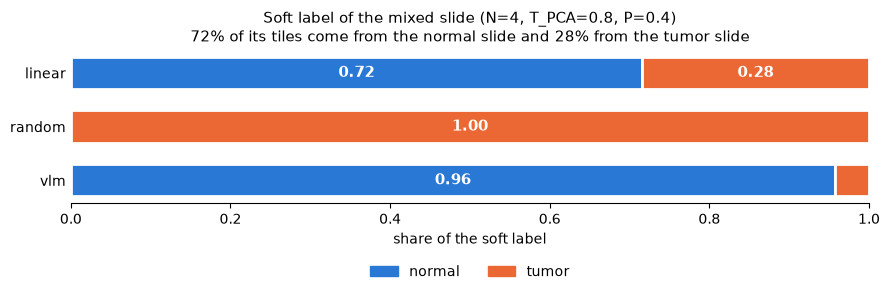

In [11]:
m = mixes[4]
f = 1.0 - m.source.float().mean().item()
idx = torch.arange(len(m.source))
w_ref, w_mov = vlm_evidence_weights(ref["scores"], mov["scores"], m.source, idx, m.moving_index, y_ref, y_mov)

targets = {
    method: soft_cls_target(y_ref, y_mov, len(CLASSES), f, method, rng=1, w_r=w_ref, w_m=w_mov)
    for method in ("linear", "random", "vlm")
}
print(f"reference: {CLASSES[y_ref]}, moving: {CLASSES[y_mov]}, share of reference tiles: {f:.2f}")
print(f"VLM evidence: reference {w_ref:.1f}, moving {w_mov:.1f}")

CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
for method, t in targets.items():
    print(f"{method:>6}: " + ", ".join(f"{c} {v:.2f}" for c, v in zip(CLASSES, t.tolist())))

fig, ax = plt.subplots(figsize=(9, 3.4))
for row, (method, t) in enumerate(targets.items()):
    left = 0.0
    for k, v in enumerate(t.tolist()):
        if v <= 0:
            continue
        ax.barh(row, v, left=left, height=0.6, color=CLASS_COLORS[k], edgecolor="white", linewidth=2)
        if v >= 0.1:
            ax.text(left + v / 2, row, f"{v:.2f}", ha="center", va="center", color="white", fontsize=11, weight="bold")
        left += v
ax.set_yticks(range(len(targets)))
ax.set_yticklabels(list(targets))
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of the soft label")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=CLASS_COLORS[k], label=c) for k, c in enumerate(CLASSES)], loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=len(CLASSES), frameon=False)
ax.set_title(
    f"Soft label of the mixed slide (N=4, T_PCA={T_PCA}, P={P})\n"
    f"{f:.0%} of its tiles come from the {CLASSES[y_ref]} slide and {1 - f:.0%} from the {CLASSES[y_mov]} slide",
    fontsize=11,
)
plt.tight_layout()
plt.show()